# 02 — Image Segmentation & HOG

**Phụ trách:** Tiến · **Chủ đề:** Chapter 4 — *Exploring Image Data*  
**Mục tiêu:** khảo sát phép phân ngưỡng trên ảnh CIFAR-10 và tìm hiểu cách trích xuất đặc trưng Histogram of Oriented Gradients (HOG).

Notebook sử dụng ảnh đầu tiên trong tập huấn luyện (`x_train[0]`) để minh họa các bước xử lý. Ngưỡng `100` và cách chuyển ảnh RGB sang ảnh xám bằng trung bình ba kênh được lựa chọn theo ví dụ trong sách. Phần so sánh các ngưỡng `60`, `100` và `140` là nội dung mở rộng của nhóm.

> Thực nghiệm tập trung minh họa các phép biến đổi ảnh, không huấn luyện mô hình. Do không có mặt nạ phân đoạn chuẩn (ground truth), tỷ lệ pixel được chọn chỉ mô tả kết quả của phép phân ngưỡng, không thể hiện độ chính xác phân đoạn.


## 01. Chuẩn bị môi trường và lấy ảnh CIFAR-10

Hàm `keras.datasets.cifar10.load_data()` được sử dụng để tải bộ dữ liệu CIFAR-10 hoặc đọc dữ liệu đã lưu trong bộ nhớ đệm. Tập dữ liệu không được lưu trực tiếp trong repository. Notebook chọn `x_train[0]` làm ảnh khảo sát và sử dụng cùng ảnh này cho cả phân ngưỡng lẫn trích xuất HOG; nhãn tương ứng được in ra để nhận diện mẫu.


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2567s 15us/step
Ảnh mẫu: x_train[0] — lớp 6 (frog)
Shape: (32, 32, 3); dtype: uint8
Miền giá trị RGB: 0–255
Kết quả sẽ lưu tại: C:\N4_HKI\PR_Seminar_BaKhi\outputs\tien


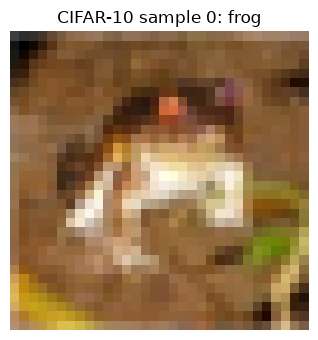

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from keras.datasets import cifar10
from skimage.feature import hog

project_root = next(
    (
        folder
        for folder in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (folder / "notebooks").is_dir() and (folder / "outputs").is_dir()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Không tìm thấy gốc repo. Hãy mở toàn bộ PR_Seminar_BaKhi trong VS Code."
    )

OUTPUT_DIR = project_root / "outputs" / "tien"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

(x_train, y_train), _ = cifar10.load_data()
sample_image = x_train[0]
sample_label = int(y_train[0, 0])
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]

assert sample_image.shape == (32, 32, 3)
assert sample_image.dtype == np.uint8
assert 0 <= sample_label < len(class_names)

print(f"Ảnh mẫu: x_train[0] — lớp {sample_label} ({class_names[sample_label]})")
print(f"Shape: {sample_image.shape}; dtype: {sample_image.dtype}")
print(f"Miền giá trị RGB: {sample_image.min()}–{sample_image.max()}")
print(f"Kết quả sẽ lưu tại: {OUTPUT_DIR}")

plt.figure(figsize=(3.5, 3.5))
plt.imshow(sample_image)
plt.title(f"CIFAR-10 sample 0: {class_names[sample_label]}")
plt.axis("off")
plt.tight_layout()
plt.show()


## 02. Segmentation bằng ngưỡng 100

Trước tiên, ảnh RGB được chuyển sang ảnh xám bằng cách lấy trung bình ba kênh màu. Sau đó, mỗi pixel có cường độ lớn hơn 100 được gán giá trị 255, trong khi các pixel còn lại được gán giá trị 0 để tạo mặt nạ nhị phân. Phép biến đổi này làm nổi bật các vùng sáng hơn ngưỡng và giảm độ phức tạp của ảnh, nhờ đó kết quả thuận tiện hơn cho việc quan sát hoặc xử lý tiếp theo mà không đòi hỏi nhiều tính toán. Tuy nhiên, do chỉ dựa trên cường độ sáng, phương pháp này không nhận biết ngữ nghĩa của đối tượng và có thể phân tách kém khi độ sáng của đối tượng gần với độ sáng của nền.

Ngưỡng: 100 (pixel được chọn khi gray > 100)
Pixel được chọn: 41.21%


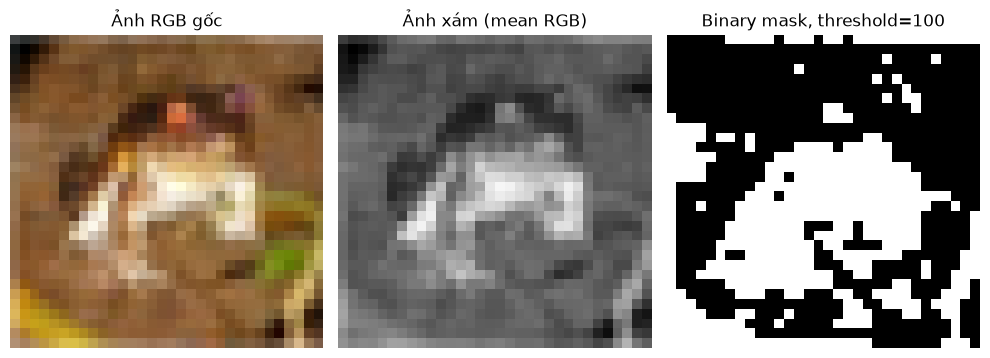

In [2]:
gray_image = np.mean(sample_image, axis=2).astype(np.uint8)
threshold = 100
segmented_image = np.where(gray_image > threshold, 255, 0).astype(np.uint8)

assert gray_image.shape == sample_image.shape[:2]
assert set(np.unique(segmented_image)).issubset({0, 255})

selected_percent_100 = np.mean(gray_image > threshold) * 100
print(f"Ngưỡng: {threshold} (pixel được chọn khi gray > {threshold})")
print(f"Pixel được chọn: {selected_percent_100:.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(sample_image)
axes[0].set_title("Ảnh RGB gốc")
axes[1].imshow(gray_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Ảnh xám (mean RGB)")
axes[2].imshow(segmented_image, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Binary mask, threshold=100")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_threshold_100.png", dpi=180, bbox_inches="tight")
plt.show()


## 03. Mở rộng: so sánh ngưỡng 60 / 100 / 140

Trong phép so sánh này, ảnh xám được giữ cố định và chỉ giá trị ngưỡng được thay đổi. Với điều kiện chọn pixel `gray > threshold`, ngưỡng càng cao thì tập pixel được chọn không thể tăng; vì vậy, tỷ lệ pixel được giữ lại có thể giảm hoặc không đổi. Việc so sánh giúp quan sát ảnh hưởng của ngưỡng đến mặt nạ đầu ra, nhưng tỷ lệ này không cho biết mức độ phân đoạn chính xác nếu chưa đối chiếu với nhãn chuẩn.


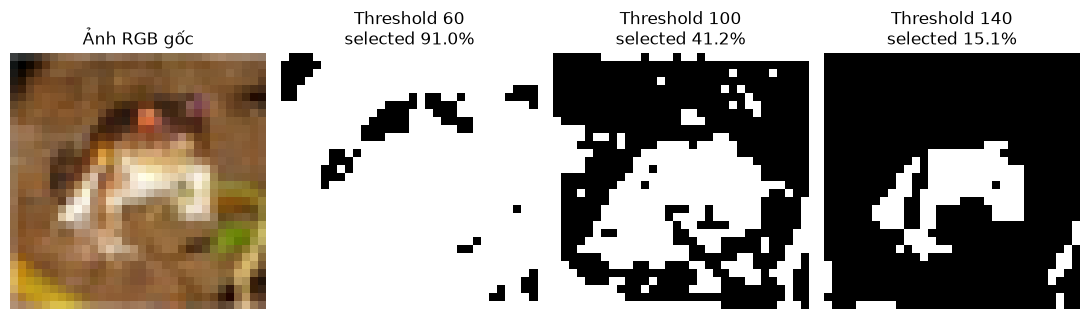

Tỷ lệ pixel được chọn (gray > threshold):
  threshold= 60:  91.02%
  threshold=100:  41.21%
  threshold=140:  15.14%
Lưu ý: đây không phải accuracy/IoU; không có ground-truth mask để đánh giá.


In [3]:
thresholds = (60, 100, 140)
fig, axes = plt.subplots(1, len(thresholds) + 1, figsize=(11, 3.3))
axes[0].imshow(sample_image)
axes[0].set_title("Ảnh RGB gốc")
axes[0].axis("off")

selected_percentages = []
for ax, value in zip(axes[1:], thresholds):
    mask = gray_image > value
    selected_percent = np.mean(mask) * 100
    selected_percentages.append(selected_percent)
    ax.imshow(mask, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Threshold {value}\nselected {selected_percent:.1f}%")
    ax.axis("off")

assert all(
    earlier >= later
    for earlier, later in zip(selected_percentages, selected_percentages[1:])
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_threshold_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

print("Tỷ lệ pixel được chọn (gray > threshold):")
for value, percent in zip(thresholds, selected_percentages):
    print(f"  threshold={value:3d}: {percent:6.2f}%")
print("Lưu ý: đây không phải accuracy/IoU; không có ground-truth mask để đánh giá.")


## 04. Trích xuất đặc trưng HOG

Histogram of Oriented Gradients (HOG) mô tả cấu trúc hình dạng cục bộ thông qua hướng và độ lớn của gradient. Trong notebook, hàm `skimage.feature.hog` được áp dụng trên ảnh xám với `pixels_per_cell=(8, 8)`, `cells_per_block=(2, 2)` và `visualize=True`; số hướng gradient được giữ ở giá trị mặc định là 9. Thay vì sử dụng trực tiếp giá trị của từng pixel, HOG tổng hợp thông tin về các cạnh thành một vector đặc trưng. Cách biểu diễn này thường gọn hơn ảnh RGB ban đầu và có thể được dùng làm đầu vào cho các mô hình phân loại ảnh. Bên cạnh đó, việc chuẩn hóa trên từng block giúp đặc trưng ít nhạy hơn với những thay đổi vừa phải về độ sáng và độ tương phản. Hình minh họa trong notebook cho thấy đặc trưng HOG được trích xuất, chứ không phải kết quả phân loại; riêng bước HOG không dự đoán nhãn cho ảnh.

HOG feature vector shape: (324,)
Số giá trị đặc trưng: 324
Giải thích: gradient được gom theo hướng trong từng cell; các block chuẩn hóa lân cận giúp mô tả cạnh bớt nhạy với thay đổi độ sáng tổng thể.


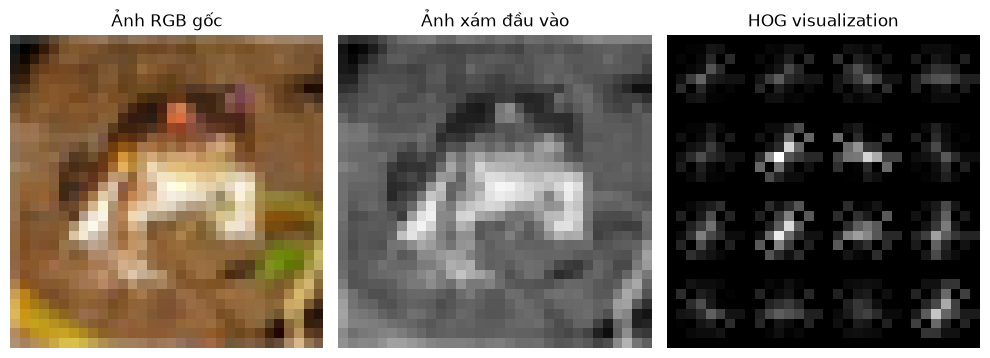

In [4]:
hog_features, hog_image = hog(
    gray_image,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
)

print(f"HOG feature vector shape: {hog_features.shape}")
print(f"Số giá trị đặc trưng: {hog_features.size}")
print(
    "Giải thích: gradient được gom theo hướng trong từng cell; các block "
    "chuẩn hóa lân cận giúp mô tả cạnh bớt nhạy với thay đổi độ sáng tổng thể."
)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(sample_image)
axes[0].set_title("Ảnh RGB gốc")
axes[1].imshow(gray_image, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Ảnh xám đầu vào")
axes[2].imshow(hog_image, cmap="gray")
axes[2].set_title("HOG visualization")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_hog_visualization.png", dpi=180, bbox_inches="tight")
plt.show()


## 05. Kết luận và giới hạn

- Phép phân ngưỡng chuyển ảnh xám thành mặt nạ nhị phân dựa trên cường độ pixel. Khi thay đổi ngưỡng, số lượng pixel được chọn cũng thay đổi.
- Tỷ lệ pixel được chọn chỉ mô tả mặt nạ đầu ra, không thể hiện mặt nạ có khớp với đối tượng cần phân đoạn hay không. Việc đánh giá cần có nhãn chuẩn và các chỉ số phù hợp.
- HOG biểu diễn thông tin cạnh và hình dạng cục bộ dưới dạng vector đặc trưng. Hình trực quan hóa hỗ trợ quan sát đặc trưng, nhưng không đủ để kết luận về chất lượng phân loại.
- Thực nghiệm chỉ khảo sát một ảnh CIFAR-10 và không huấn luyện hoặc đánh giá bộ phân loại; do đó, kết quả chỉ có ý nghĩa minh họa, không đại diện cho toàn bộ tập dữ liệu.

### Tài liệu tham khảo

1. Vijaya Kumar Suda (2024), *Data Labeling in Machine Learning with Python*, Chapter 4, “Exploring Image Data”, ví dụ segmentation/HOG, trang in 98–101 (số trang thấy trong kết quả tìm kiếm Google Books). [Google Books](https://books.google.com.vn/books?id=2u_xEAAAQBAJ).
2. [scikit-image: Histogram of Oriented Gradients example](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html) — tham khảo API và cách trực quan hóa.

Phần trình bày được diễn giải lại phục vụ seminar và không thay thế nội dung đầy đủ của tài liệu tham khảo. Ngưỡng 100 được dùng theo ví dụ trong sách; việc so sánh các ngưỡng 60, 100 và 140 là phần mở rộng của nhóm.
